In [16]:
#Import Libraries

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
#Set Paths

BASE_DIR = os.path.dirname(os.getcwd())
INPUT_PATH = os.path.join(BASE_DIR, "outputs", "cleaned_mobile_reviews.csv")
CHARTS_PATH = os.path.join(BASE_DIR, "outputs", "charts")

os.makedirs(CHARTS_PATH, exist_ok=True)

print("Input file:", INPUT_PATH)
print("Charts folder:", CHARTS_PATH)

Input file: c:\Users\acer\Documents\Global_Mobile_Reviews\outputs\cleaned_mobile_reviews.csv
Charts folder: c:\Users\acer\Documents\Global_Mobile_Reviews\outputs\charts


In [18]:
#Load Cleaned Dataset

df = pd.read_csv(INPUT_PATH)
print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (49485, 22)


In [19]:
#Display First 5 Rows

df.head()

,review_id,customer_name,age,brand,model,price_usd,price_local,currency,exchange_rate_to_usd,rating,...,language,review_date,verified_purchase,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes,source
0,1,Aryan Maharaj,45,Realme,Realme 12 Pro,337.31,27996.73,INR,83.00,2.0,...,Hindi,2023-11-06,True,1,1,3,2,1,1,Amazon
1,2,Davi Miguel Sousa,18,Realme,Realme 12 Pro,307.78,1754.35,BRL,5.70,4.0,...,Portuguese,2023-03-30,True,3,2,4,3,2,5,Flipkart
2,3,Pahal Balay,27,Google,Pixel 6,864.53,71755.99,INR,83.00,4.0,...,Hindi,2022-12-07,True,3,5,3,2,4,8,AliExpress
3,4,David Guzman,19,Xiaomi,Redmi Note 13,660.94,2425.65,AED,3.67,3.0,...,English,2025-03-11,False,1,3,2,1,2,3,Amazon
4,5,Yago Leão,38,Motorola,Edge 50,792.13,4515.14,BRL,5.70,3.0,...,Portuguese,2023-09-29,True,3,3,2,2,1,0,BestBuy


In [20]:
#Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49485 entries, 0 to 49484
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   review_id             49485 non-null  int64  
 1   customer_name         49485 non-null  str    
 2   age                   49485 non-null  int64  
 3   brand                 49485 non-null  str    
 4   model                 49485 non-null  str    
 5   price_usd             49485 non-null  float64
 6   price_local           49485 non-null  float64
 7   currency              49485 non-null  str    
 8   exchange_rate_to_usd  49485 non-null  float64
 9   rating                49485 non-null  float64
 10  sentiment             49485 non-null  str    
 11  country               49485 non-null  str    
 12  language              49485 non-null  str    
 13  review_date           49485 non-null  str    
 14  verified_purchase     49485 non-null  bool   
 15  battery_life_rating   49485 no

In [21]:
#Statistical Summary

df.describe().T

,count,mean,std,min,25%,50%,75%,max
review_id,49485.0,25006.850581,14435.276906,1.00,12506.00,25007.00,37514.00,50000.00
age,49485.0,30.077822,8.934166,18.00,23.00,29.00,36.00,65.00
price_usd,49485.0,689.634094,310.264852,180.02,450.68,637.11,900.95,1499.89
price_local,49485.0,8338.655405,20485.675165,141.09,591.52,1053.81,2917.69,124397.08
exchange_rate_to_usd,49485.0,12.104791,26.620494,0.78,1.00,1.38,5.70,83.00
rating,49485.0,3.133475,1.232766,1.00,2.00,3.00,4.00,5.00
battery_life_rating,49485.0,2.718440,1.348783,1.00,1.00,3.00,4.00,5.00
camera_rating,49485.0,2.718117,1.344814,1.00,1.00,3.00,4.00,5.00
performance_rating,49485.0,2.720299,1.349469,1.00,1.00,3.00,4.00,5.00
design_rating,49485.0,2.714277,1.343793,1.00,1.00,3.00,4.00,5.00


In [25]:
#Missing Values

print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [26]:
#Duplicate Check

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [28]:
#Reviews by Brand

brand_counts = df["brand"].value_counts()
brand_counts

brand
Xiaomi      7165
Google      7163
OnePlus     7067
Apple       7058
Realme      7057
Samsung     6991
Motorola    6984
Name: count, dtype: int64

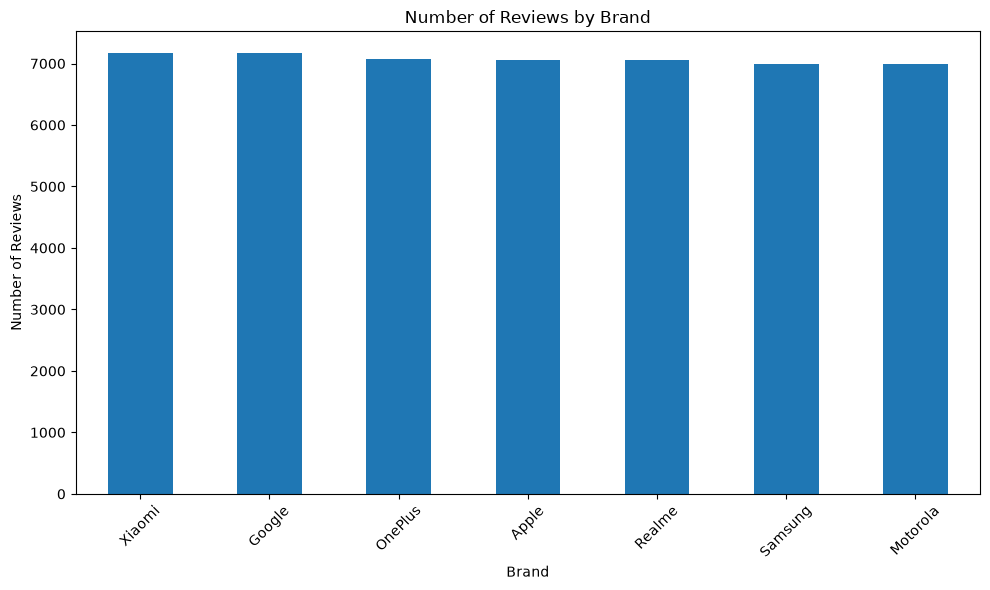

In [29]:
#Reviews by Brand Chart

plt.figure(figsize=(10, 6))

brand_counts.plot(kind="bar")

plt.title("Number of Reviews by Brand")
plt.xlabel("Brand")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "reviews_by_brand.png"))
plt.show()
plt.close()

In [30]:
#Reviews by Country

country_counts = df["country"].value_counts()
country_counts

country
USA          6402
Brazil       6380
Australia    6184
UK           6175
Germany      6148
Canada       6137
India        6095
UAE          5964
Name: count, dtype: int64

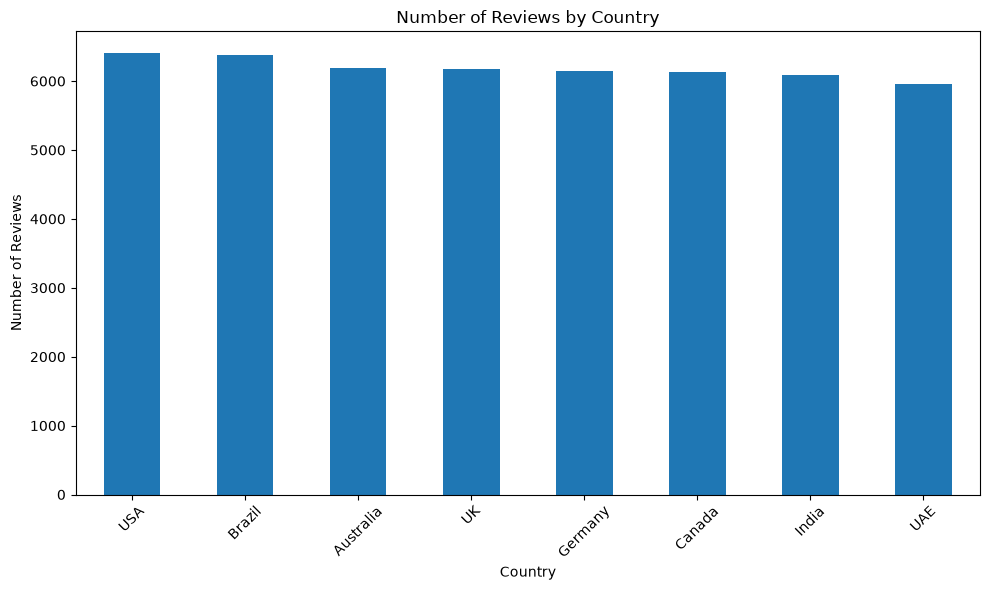

In [31]:
#Country Chart

plt.figure(figsize=(10, 6))

country_counts.plot(kind="bar")

plt.title("Number of Reviews by Country")
plt.xlabel("Country")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "reviews_by_country.png"))
plt.show()
plt.close()

In [32]:
#Rating Distribution

rating_counts = df["rating"].value_counts().sort_index()
rating_counts

rating
1.0     6028
2.0     9708
3.0    12327
4.0    14475
5.0     6947
Name: count, dtype: int64

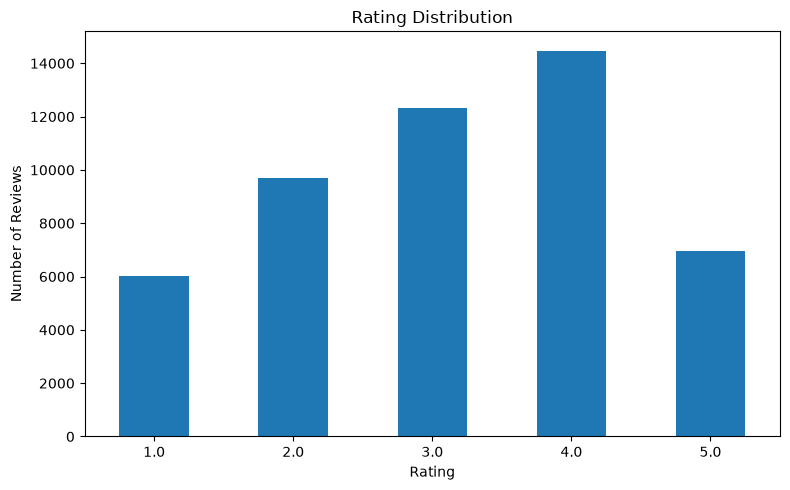

In [33]:
#Rating Chart

plt.figure(figsize=(8, 5))

rating_counts.plot(kind="bar")

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "rating_distribution.png"))
plt.show()
plt.close()

In [34]:
#Sentiment Distribution

sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

sentiment
Positive    21422
Negative    15736
Neutral     12327
Name: count, dtype: int64

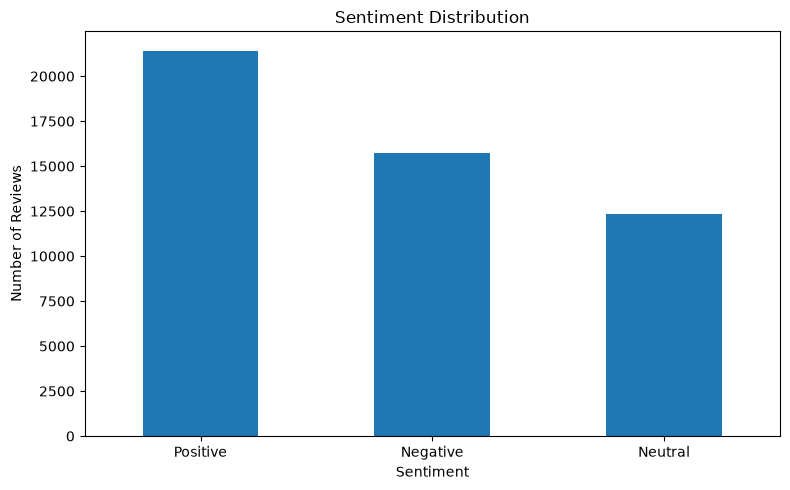

In [35]:
#Sentiment Chart

plt.figure(figsize=(8, 5))

sentiment_counts.plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "sentiment_distribution.png"))
plt.show()
plt.close()

In [ ]:
#Average Price by Brand

brand_price = (
    df.groupby("brand")["price_usd"]
    .mean()
    .sort_values(ascending=False)
)
brand_price

brand
Apple       1103.482624
Samsung      899.505527
Google       804.652393
OnePlus      672.907435
Motorola     506.019520
Xiaomi       449.475848
Realme       393.371537
Name: price_usd, dtype: float64

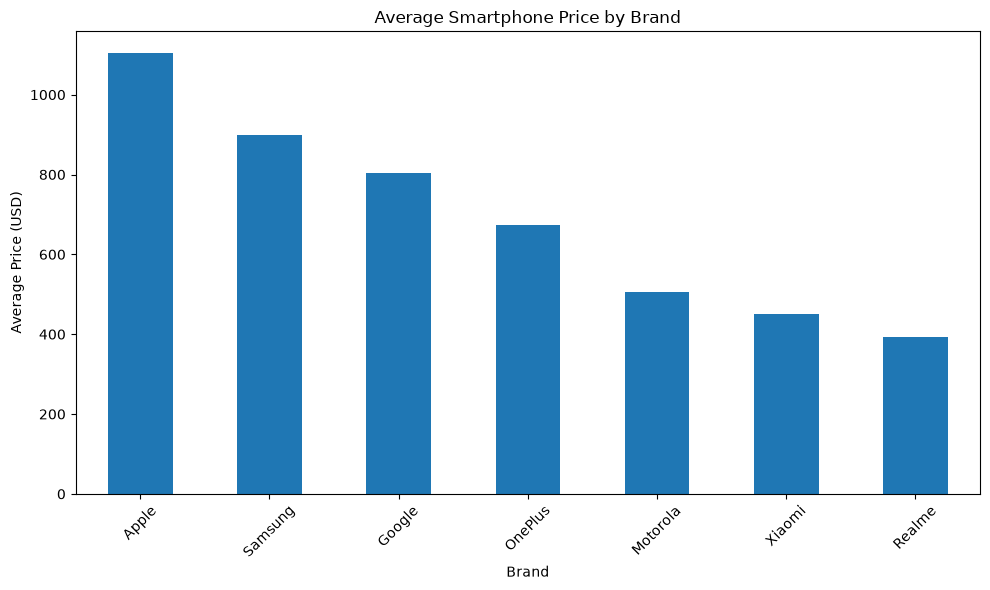

In [37]:
#Price by Brand Chart

plt.figure(figsize=(10, 6))

brand_price.plot(kind="bar")

plt.title("Average Smartphone Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "price_by_brand.png"))
plt.show()
plt.close()

In [38]:
#Average Rating by Brand

brand_rating = (
    df.groupby("brand")["rating"]
    .mean()
    .sort_values(ascending=False)
)
brand_rating

brand
Realme      3.146946
OnePlus     3.143908
Apple       3.143808
Google      3.133882
Xiaomi      3.123098
Samsung     3.121442
Motorola    3.121134
Name: rating, dtype: float64

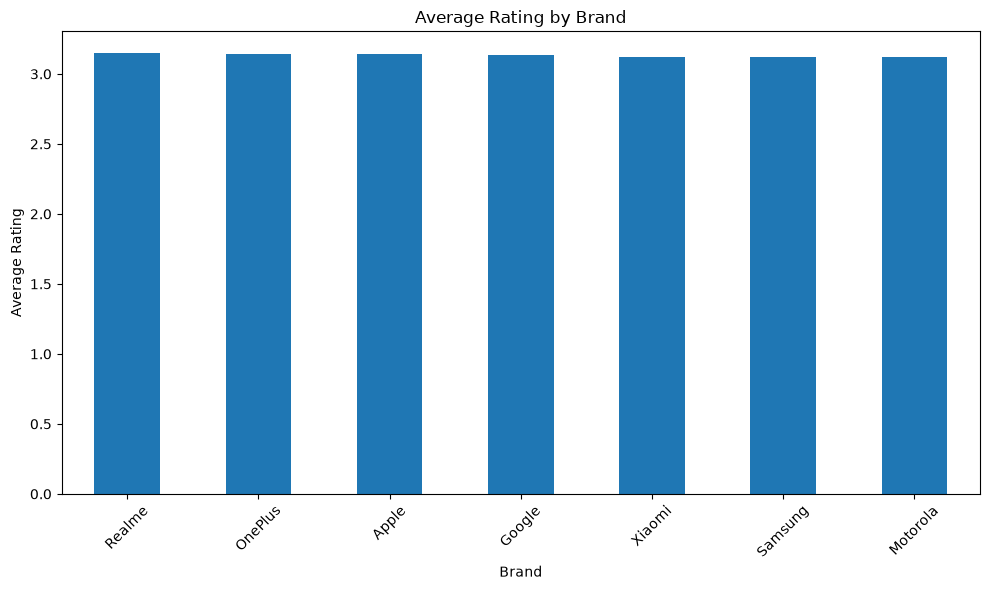

In [39]:
#Rating by Brand Chart

plt.figure(figsize=(10, 6))

brand_rating.plot(kind="bar")

plt.title("Average Rating by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "rating_by_brand.png"))
plt.show()
plt.close()

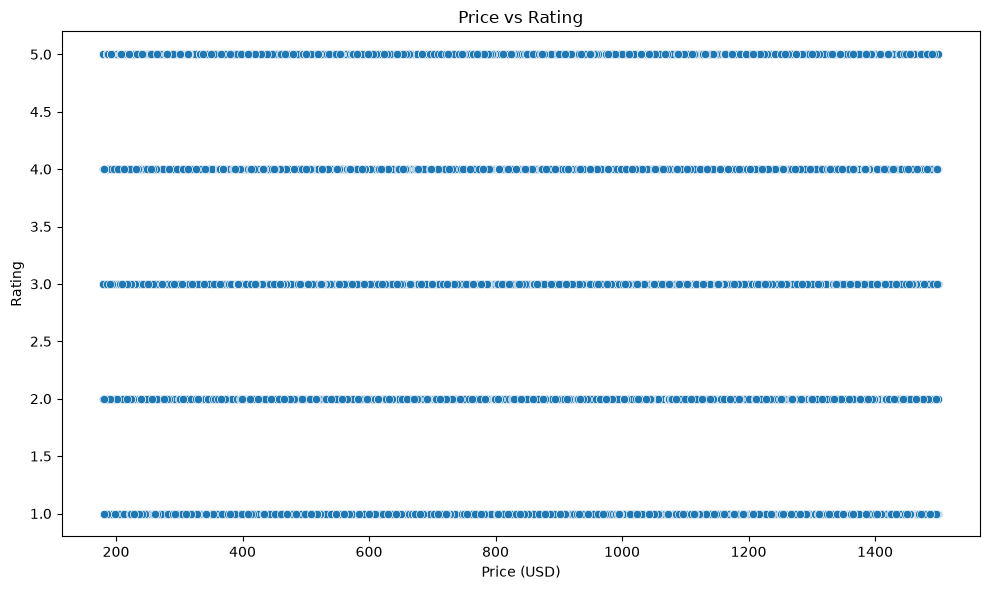

In [40]:
#Price vs Rating

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="price_usd",
    y="rating"
)
plt.title("Price vs Rating")
plt.xlabel("Price (USD)")
plt.ylabel("Rating")
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "price_vs_rating.png"))
plt.show()
plt.close()

In [41]:
#Helpful Votes by Rating

helpful_by_rating = (
    df.groupby("rating")["helpful_votes"]
    .mean()
)
helpful_by_rating

rating
1.0    1.973125
2.0    2.220849
3.0    3.524459
4.0    4.760138
5.0    4.969339
Name: helpful_votes, dtype: float64

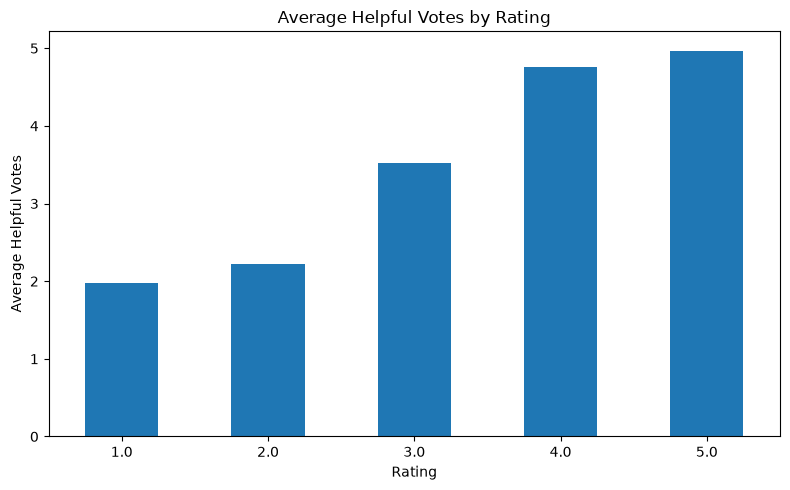

In [42]:
#Helpful Votes Chart

plt.figure(figsize=(8, 5))

helpful_by_rating.plot(kind="bar")

plt.title("Average Helpful Votes by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Helpful Votes")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "helpful_votes_by_rating.png"))
plt.show()
plt.close()

In [43]:
#Convert Review Date

df["review_date"] = pd.to_datetime(
    df["review_date"],
    errors="coerce"
)
print(df["review_date"].dtype)

datetime64[us]


In [44]:
#Reviews Over Time

reviews_over_time = (
    df.groupby(df["review_date"].dt.to_period("M"))
    .size()
)
reviews_over_time.index = reviews_over_time.index.astype(str)
reviews_over_time.head()

review_date
2022-10     494
2022-11    1324
2022-12    1381
2023-01    1354
2023-02    1320
dtype: int64

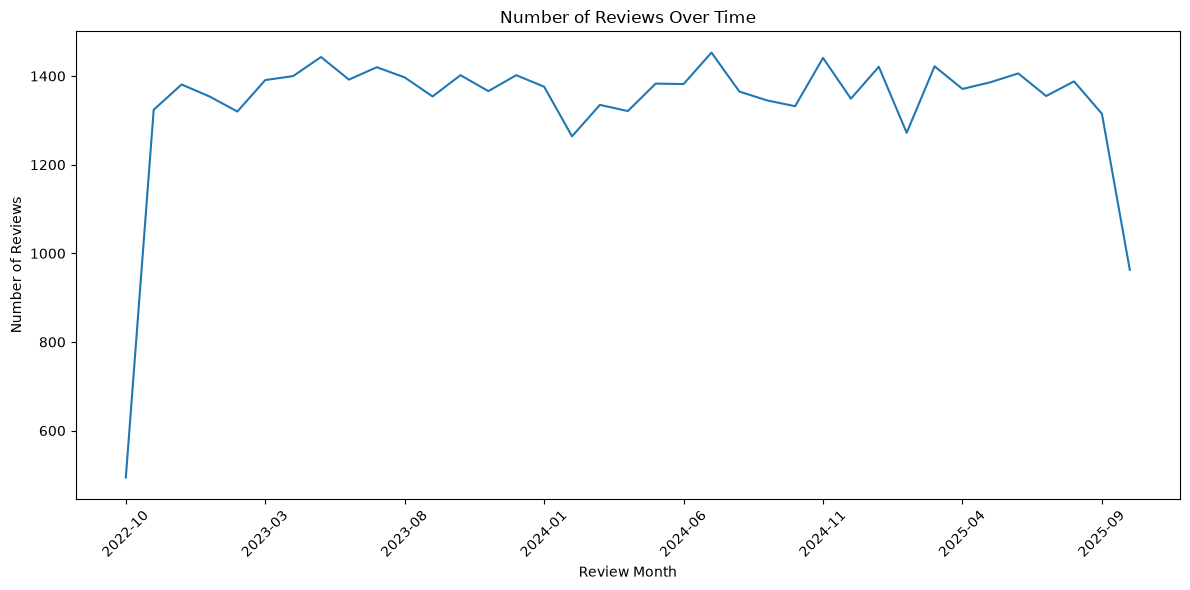

In [45]:
#Reviews Over Time Chart

plt.figure(figsize=(12, 6))

reviews_over_time.plot(kind="line")

plt.title("Number of Reviews Over Time")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "reviews_over_time.png"))
plt.show()
plt.close()

In [46]:
#Select Numerical Features

numeric_columns = [
    "age",
    "price_usd",
    "price_local",
    "exchange_rate_to_usd",
    "rating",
    "battery_life_rating",
    "camera_rating",
    "performance_rating",
    "design_rating",
    "display_rating",
    "helpful_votes"
]
numeric_df = df[numeric_columns]

In [47]:
#Correlation Matrix

correlation = numeric_df.corr()
correlation

,age,price_usd,price_local,exchange_rate_to_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes
age,1.000000,0.002164,0.003980,0.004520,0.007209,0.005144,0.008357,0.004559,0.009757,0.008269,-0.005194
price_usd,0.002164,1.000000,0.185013,-0.001116,0.001722,0.000836,0.002074,-0.004624,0.002905,-0.000307,0.002369
price_local,0.003980,0.185013,1.000000,0.894706,-0.000934,-0.005778,0.000978,0.004460,0.005466,0.001404,0.000483
exchange_rate_to_usd,0.004520,-0.001116,0.894706,1.000000,-0.002550,-0.007069,0.000095,0.004981,0.002995,-0.000214,-0.002226
rating,0.007209,0.001722,-0.000934,-0.002550,1.000000,0.753837,0.752333,0.747328,0.747517,0.749209,0.461660
battery_life_rating,0.005144,0.000836,-0.005778,-0.007069,0.753837,1.000000,0.589240,0.584548,0.586248,0.584383,0.356156
camera_rating,0.008357,0.002074,0.000978,0.000095,0.752333,0.589240,1.000000,0.580533,0.581106,0.581613,0.355393
performance_rating,0.004559,-0.004624,0.004460,0.004981,0.747328,0.584548,0.580533,1.000000,0.576414,0.580416,0.353598
design_rating,0.009757,0.002905,0.005466,0.002995,0.747517,0.586248,0.581106,0.576414,1.000000,0.579119,0.353039
display_rating,0.008269,-0.000307,0.001404,-0.000214,0.749209,0.584383,0.581613,0.580416,0.579119,1.000000,0.352161


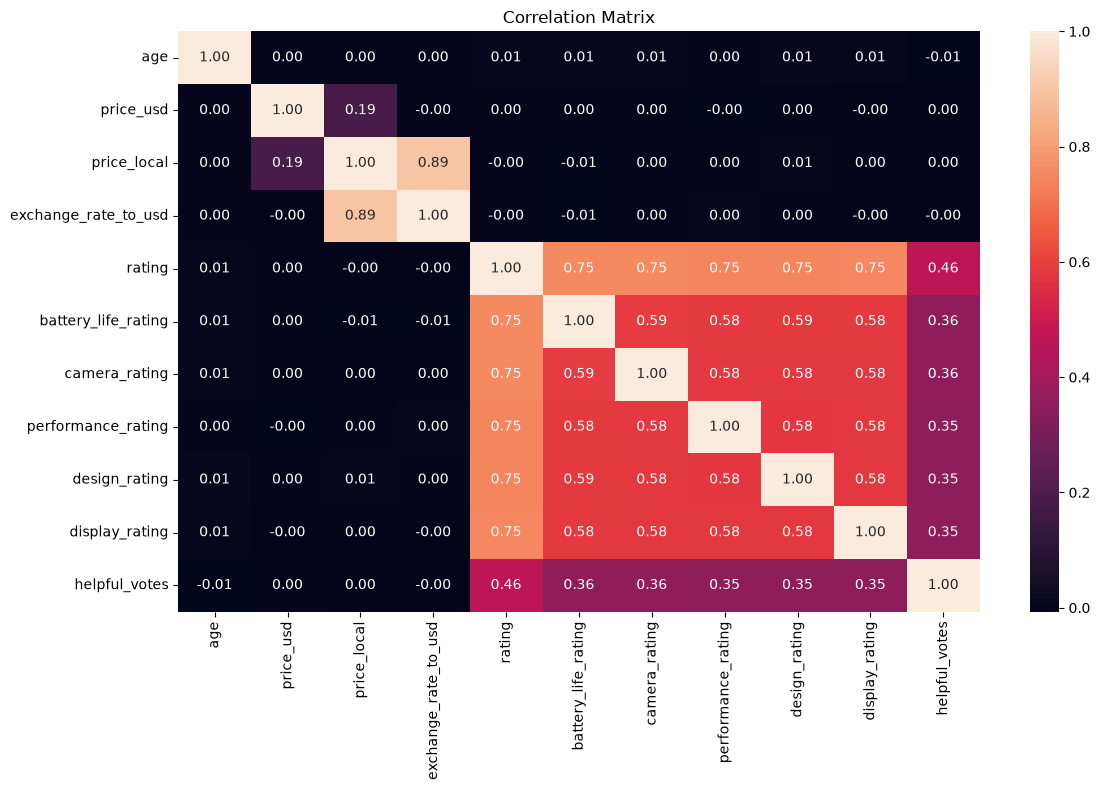

In [48]:
#Correlation Heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.tight_layout()

plt.savefig(os.path.join(CHARTS_PATH, "correlation_matrix.png"))
plt.show()
plt.close()

In [49]:
#Average Rating by Model

model_rating = (
    df.groupby("model")["rating"]
    .mean()
    .sort_values(ascending=False)
)
model_rating

model
iPhone 14          3.182643
iPhone 13          3.169617
Galaxy Note 20     3.162528
Realme 12 Pro      3.157278
OnePlus Nord 3     3.150679
OnePlus 12         3.148455
Galaxy Z Flip      3.145294
Pixel 7a           3.138934
Moto G Power       3.138793
Realme Narzo 70    3.136798
Poco X6            3.135241
Pixel 8            3.133672
OnePlus 11R        3.132974
Pixel 6            3.128868
Redmi Note 13      3.126281
Razr 40            3.120842
iPhone SE          3.120428
Mi 13 Pro          3.108309
Edge 50            3.103539
iPhone 15 Pro      3.102999
Galaxy A55         3.095211
Galaxy S24         3.083142
Name: rating, dtype: float64

In [50]:
#Top 10 Rated Models

top_models = model_rating.head(10)
top_models

model
iPhone 14          3.182643
iPhone 13          3.169617
Galaxy Note 20     3.162528
Realme 12 Pro      3.157278
OnePlus Nord 3     3.150679
OnePlus 12         3.148455
Galaxy Z Flip      3.145294
Pixel 7a           3.138934
Moto G Power       3.138793
Realme Narzo 70    3.136798
Name: rating, dtype: float64

In [51]:
#Lowest 10 Rated Models

low_models = model_rating.tail(10)
low_models

model
OnePlus 11R      3.132974
Pixel 6          3.128868
Redmi Note 13    3.126281
Razr 40          3.120842
iPhone SE        3.120428
Mi 13 Pro        3.108309
Edge 50          3.103539
iPhone 15 Pro    3.102999
Galaxy A55       3.095211
Galaxy S24       3.083142
Name: rating, dtype: float64

In [52]:
#Brand Performance

brand_performance = (
    df.groupby("brand")
    .agg(
        Reviews=("review_id", "count"),
        Average_Rating=("rating", "mean"),
        Average_Price=("price_usd", "mean")
    )
    .sort_values("Average_Rating", ascending=False)
)
brand_performance

,Reviews,Average_Rating,Average_Price
brand,,,
Realme,7057,3.146946,393.371537
OnePlus,7067,3.143908,672.907435
Apple,7058,3.143808,1103.482624
Google,7163,3.133882,804.652393
Xiaomi,7165,3.123098,449.475848
Samsung,6991,3.121442,899.505527
Motorola,6984,3.121134,506.019520


In [53]:
#List Saved Charts

print("Charts saved in:")
print(CHARTS_PATH)

print("\nFiles:")
print(os.listdir(CHARTS_PATH))

Charts saved in:
c:\Users\acer\Documents\Global_Mobile_Reviews\outputs\charts

Files:
['correlation_matrix.png', 'helpful_votes_by_rating.png', 'price_by_brand.png', 'price_vs_rating.png', 'rating_by_brand.png', 'rating_distribution.png', 'reviews_by_brand.png', 'reviews_by_country.png', 'reviews_over_time.png', 'sentiment_distribution.png']
